# Exploration des données — prêts immobiliers

Ce notebook donne un aperçu du jeu d’entraînement sans modifier les données. Il utilise le chargeur du projet pour appliquer les mêmes règles de lecture des valeurs manquantes que les scripts d’entraînement.

La cible explorée est `accepted`. Les fichiers test et gabarit sont également chargés pour suivre le parcours commun du projet, mais aucune cible du jeu test n’est utilisée. Les graphiques et statistiques restent descriptifs : ils ne démontrent pas de relation causale.

## 1. Imports et chargement

Exécuter le notebook depuis n’importe quel sous-dossier du dépôt est accepté : le projet est recherché en remontant depuis le répertoire courant. Si le dossier de données a été déplacé, modifier `data_dir` dans `config.json`.

In [33]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Repérer la racine du projet pour pouvoir importer les modules de src.
ROOT = Path.cwd().resolve()
while not (ROOT / "config.json").is_file() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if not (ROOT / "config.json").is_file():
    raise FileNotFoundError("config.json introuvable : ouvrez ce notebook depuis le dépôt du projet.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.config import load_config
from src.data import load_competition_data
from src.preprocessing import NUMERIC_COLUMNS

config = load_config(ROOT / "config.json")
data = load_competition_data(config)

X = data.features.reset_index(drop=True)
y = data.target.reset_index(drop=True)
df = X.copy()
df[config.target_column] = y

print(f"Racine du projet : {ROOT}")
print(f"Dossier des données : {config.data_dir}")
print(f"Train : {X.shape[0]:,} lignes × {X.shape[1]:,} variables explicatives")
print(f"Test : {data.test_features.shape[0]:,} lignes")
print(f"Gabarit : {data.submission_template.shape}")

C:\Documents\Cours\M2\P1\Supervise\App_sup_M2\src\data.py:50: DtypeWarning: Columns (34: co-applicant_ethnicity-1, 38: co-applicant_race-1) have mixed types. Specify dtype option on import or set low_memory=False.
  return pd.read_csv(


Racine du projet : C:\Documents\Cours\M2\P1\Supervise\App_sup_M2
Dossier des données : C:\Documents\Cours\M2\P1\Supervise\App_sup_M2\data
Train : 105,000 lignes × 56 variables explicatives
Test : 45,000 lignes
Gabarit : (45000, 2)


C:\Documents\Cours\M2\P1\Supervise\App_sup_M2\src\data.py:50: DtypeWarning: Columns (34: co-applicant_ethnicity-1, 38: co-applicant_race-1) have mixed types. Specify dtype option on import or set low_memory=False.
  return pd.read_csv(


## 2. Aperçu du schéma

In [4]:
display(df.head())
display(df.dtypes.value_counts().rename_axis("type").to_frame("nombre de colonnes"))
print("Colonnes explicatives :")
print(", ".join(X.columns))

,loan_amount,loan_to_value_ratio,property_value,income,loan_term,total_units,state_code,derived_msa-md,county_code,conforming_loan_limit,...,initially_payable_to_institution,aus-1,tract_population,tract_minority_population_percent,ffiec_msa_md_median_family_income,tract_to_msa_income_percentage,tract_owner_occupied_units,tract_one_to_four_family_homes,tract_median_age_of_housing_units,accepted
0,705000.0,46.823,1495000.0,655.0,360.0,1.0,CA,34900,6055.0,C,...,1,1,4493,49.83,121100,78,1094,1486,55,1
1,295000.0,53.000,555000.0,63.0,360.0,1.0,NC,99999,37113.0,C,...,1,6,1604,13.22,71500,140,547,2188,39,1
2,305000.0,80.000,385000.0,109.0,360.0,1.0,VA,40060,51087.0,C,...,1,1,4780,40.92,110000,71,781,1527,53,1
3,765000.0,58.970,1305000.0,190.0,360.0,1.0,NC,16740,37179.0,C,...,1,1,7126,32.88,100300,273,1991,2094,0,1
4,1775000.0,60.000,2955000.0,15675.0,360.0,1.0,FL,33124,12086.0,NC,...,1,1,6006,53.48,79400,167,1043,723,56,0


,nombre de colonnes
type,
int64,35
str,13
float64,7
object,2


Colonnes explicatives :
loan_amount, loan_to_value_ratio, property_value, income, loan_term, total_units, state_code, derived_msa-md, county_code, conforming_loan_limit, derived_loan_product_type, derived_dwelling_category, loan_type, lien_status, preapproval, reverse_mortgage, open-end_line_of_credit, business_or_commercial_purpose, negative_amortization, interest_only_payment, balloon_payment, other_nonamortizing_features, construction_method, occupancy_type, manufactured_home_secured_property_type, manufactured_home_land_property_interest, applicant_credit_score_type, co-applicant_credit_score_type, debt_to_income_ratio, derived_ethnicity, derived_race, derived_sex, applicant_ethnicity-1, co-applicant_ethnicity-1, applicant_ethnicity_observed, co-applicant_ethnicity_observed, applicant_race-1, co-applicant_race-1, applicant_race_observed, co-applicant_race_observed, applicant_sex, co-applicant_sex, applicant_sex_observed, co-applicant_sex_observed, applicant_age, co-applicant_age, s

## 3. Répartition de la cible

Le challenge est évalué avec le ROC-AUC. Les proportions ci-dessous aident notamment à comprendre le déséquilibre éventuel des classes. Le ROC-AUC se calcule à partir des probabilités prédites, pas de classes obtenues avec un seuil.

In [5]:
target_counts = y.value_counts().sort_index()
target_summary = pd.DataFrame({
    "effectif": target_counts,
    "proportion": y.value_counts(normalize=True).sort_index(),
})
display(target_summary)

,effectif,proportion
accepted,,
0,15756,0.150057
1,89244,0.849943


## 4. Valeurs manquantes

Les marqueurs de valeurs manquantes numériques sont interprétés par le chargeur du projet. Les champs catégoriels vides sont également comptés comme manquants ici, conformément au prétraitement des modèles.

In [8]:
missing_mask = pd.DataFrame(
    {
        column: X[column].isna()
        | X[column].astype("string").str.strip().eq("").fillna(False)
        for column in X.columns
    },
    index=X.index,
)
missing_summary = pd.DataFrame({
    "nombre": missing_mask.sum(),
    "pourcentage": 100 * missing_mask.mean(),
}).sort_values("pourcentage", ascending=False)
display(missing_summary.head(20))

,nombre,pourcentage
co-applicant_age,58693,55.898095
loan_to_value_ratio,11874,11.308571
debt_to_income_ratio,7679,7.313333
property_value,4756,4.529524
income,4578,4.36
loan_term,3307,3.149524
applicant_age,3088,2.940952
county_code,1339,1.275238
state_code,824,0.784762
conforming_loan_limit,437,0.41619


In [21]:
target_rate = pd.concat([X, y.rename("target")], axis=1)

categorical_columns = X.select_dtypes(include=["object", "category", "string"]).columns
columns_with_missing = missing_summary.index[(missing_summary["nombre"] > 0)
                                             & missing_summary.index.isin(categorical_columns)]

results = {}

for column in columns_with_missing:
    summary = (
        target_rate.groupby(column, dropna=False)["target"]
        .agg(nombre="size", taux_positif="mean")
    )
    summary["pourcentage"] = 100 * summary["taux_positif"]

    results[column] = summary.drop(columns="taux_positif").sort_values(
        "pourcentage", ascending=False
    )

for column, summary in results.items():
    print(f"\n--- {column} ---")
    display(summary)


--- co-applicant_age ---


,nombre,pourcentage
co-applicant_age,,
25-34,14076,89.258312
65-74,3384,89.154846
35-44,11285,88.453700
55-64,6102,86.725664
45-54,7380,86.219512
>74,1118,85.152057
,58693,82.849744
<25,2962,82.613099



--- debt_to_income_ratio ---


,nombre,pourcentage
debt_to_income_ratio,,
44,4165,92.484994
39,3403,92.300911
43,3657,92.261416
37,2978,92.108798
38,3073,92.059876
49,5793,92.042120
30%-<36%,13624,91.735173
36,2746,91.660597
40,3500,91.657143



--- applicant_age ---


,nombre,pourcentage
applicant_age,,
,3088,87.467617
25-34,30933,86.545114
65-74,5903,85.363375
35-44,27055,85.215302
>74,1828,84.956236
55-64,11993,84.132411
45-54,17437,83.385904
<25,6763,81.250924


... (10 outputs left out)


--- co-applicant_ethnicity-1 ---


,nombre,pourcentage
co-applicant_ethnicity-1,,
12.0,10,100.000000
4.0,884,90.610860
2.0,27406,89.173904
2.0,5004,88.828937
4.0,168,88.095238
3.0,5740,85.278746
1.0,1037,84.956606
3.0,1035,84.444444
1.0,5604,83.690221



--- co-applicant_race-1 ---


,nombre,pourcentage
co-applicant_race-1,,
23.0,29,100.000000
43.0,3,100.000000
41.0,1,100.000000
44.0,7,100.000000
24.0,1,100.000000
7.0,281,92.882562
22.0,47,91.489362
2.0,1005,90.746269
2.0,2148,90.689013


### Loan_to_value_ratio

In [37]:
bins = [0, 50, 60, 70, 80, 90, 100, 110, 120, 130, 150, np.inf]

labels = [
    "[0, 50]",
    "]50, 60]",
    "]60, 70]",
    "]70, 80]",
    "]80, 90]",
    "]90, 100]",
    "]100, 110]",
    "]110, 120]",
    "]120, 130]",
    "]130, 150]",
    ">150",
]

loan_to_value_bin = pd.cut(
    X["loan_to_value_ratio"],
    bins=bins,
    labels=labels,
    include_lowest=True
)

summary = (
    pd.DataFrame({
        "loan_to_value_bin": loan_to_value_bin,
        "target": y
    })
    .groupby("loan_to_value_bin", observed=False)["target"]
    .agg(nombre="size", taux_positif="mean")
)

summary["pourcentage"] = 100 * summary["taux_positif"]

display(summary.drop(columns="taux_positif").round(2))

,nombre,pourcentage
loan_to_value_bin,,
"[0, 50]",5932,90.61
"]50, 60]",3966,91.75
"]60, 70]",6371,90.77
"]70, 80]",23330,90.90
"]80, 90]",11147,89.00
"]90, 100]",36669,87.87
"]100, 110]",5241,84.22
"]110, 120]",174,50.57
"]120, 130]",97,64.95


### Property_value

In [25]:
bins = [0, 50_000, 100_000, 200_000, 300_000, 500_000, 1_000_000, np.inf]

labels = [
    "[0, 50k]",
    "[50k, 100k]",
    "]100k, 200k]",
    "]200k, 300k]",
    "]300k, 500k]",
    "]500k, 1M]",
    ">1M",
]

df = pd.DataFrame({
    "property_value": X["property_value"],
    "target": y
})

df["tranche"] = pd.cut(
    df["property_value"],
    bins=bins,
    labels=labels,
    include_lowest=True
)

summary = (
    df.groupby("tranche", observed=False)["target"]
    .agg(nombre="size", taux_positif="mean")
)

summary["pourcentage"] = 100 * summary["taux_positif"]
summary = summary.drop(columns="taux_positif")

display(summary)

,nombre,pourcentage
tranche,,
"[0, 50k]",661,34.795764
"[50k, 100k]",3775,44.821192
"]100k, 200k]",13948,72.892171
"]200k, 300k]",19887,88.052497
"]300k, 500k]",32741,90.742494
"]500k, 1M]",22739,91.336470
>1M,6493,90.050824


### Income

In [31]:
bins = [0, 20, 30, 40, 50, 60, 75, 100, 150, np.inf]

labels = [
    "[0, 20k]",
    "]20k, 30k]",
    "]30k, 40k]",
    "]40k, 50k]",
    "]50k, 60k]",
    "]60k, 75k]",
    "]75k, 100k]",
    "]100k, 150k]",
    ">150k",
]

df = pd.DataFrame({
    "income": X["income"],
    "target": y
})

df["tranche"] = pd.cut(
    df["income"],
    bins=bins,
    labels=labels,
    include_lowest=True
)

summary = (
    df.groupby("tranche", observed=False)["target"]
    .agg(nombre="size", taux_positif="mean")
)

summary["pourcentage"] = 100 * summary["taux_positif"]
summary = summary.drop(columns="taux_positif")

display(summary)

,nombre,pourcentage
tranche,,
"[0, 20k]",1701,46.560847
"]20k, 30k]",1297,43.253662
"]30k, 40k]",3110,56.816720
"]40k, 50k]",5319,70.201166
"]50k, 60k]",6570,76.849315
"]60k, 75k]",10990,82.811647
"]75k, 100k]",17400,86.459770
"]100k, 150k]",23556,89.811513
>150k,30451,92.308955


### Loan_term

In [36]:
bins = [0, 60, 120, 180, 240, 300, 360, np.inf]

labels = [
    "[0, 60]",
    "]60, 120]",
    "]120, 180]",
    "]180, 240]",
    "]240, 300]",
    "]300, 360]",
    ">360",
]

loan_term_bin = pd.cut(
    X["loan_term"],
    bins=bins,
    labels=labels,
    include_lowest=True
)

summary = (
    pd.DataFrame({
        "loan_term_bin": loan_term_bin,
        "target": y
    })
    .groupby("loan_term_bin", observed=False)["target"]
    .agg(nombre="size", taux_positif="mean")
)

summary["pourcentage"] = 100 * summary["taux_positif"]

display(summary.drop(columns="taux_positif").round(2))

,nombre,pourcentage
loan_term_bin,,
"[0, 60]",2301,86.79
"]60, 120]",1546,83.89
"]120, 180]",2520,82.98
"]180, 240]",2372,54.26
"]240, 300]",6051,28.97
"]300, 360]",85847,89.93
>360,1056,69.60


## 5. Variables numériques continues

La liste numérique explicite est partagée avec le prétraitement du projet. Les codes, tranches d’âge, catégories géographiques et ratios codés comme modalités restent des variables catégorielles dans le pipeline.

,count,mean,std,min,25%,50%,75%,max
loan_amount,105000.0,379120.476190,1.878547e+06,5000.0,175000.00000,285000.00,435000.00,3.750050e+08
loan_to_value_ratio,93126.0,6528.788724,1.966146e+06,0.5,75.11875,90.00,96.50,6.000000e+08
property_value,100244.0,515903.694984,5.675571e+06,5000.0,235000.00000,355000.00,545000.00,1.581075e+09
income,100422.0,154.181912,3.525278e+02,-657.0,70.00000,107.00,169.00,7.100000e+04
loan_term,101693.0,337.748695,6.640836e+01,1.0,360.00000,360.00,360.00,4.800000e+02
total_units,104563.0,1.038599,2.567021e-01,1.0,1.00000,1.00,1.00,4.000000e+00
tract_population,105000.0,4759.982200,2.310308e+03,0.0,3362.00000,4490.00,5842.00,3.019900e+04
tract_minority_population_percent,105000.0,36.635950,2.570179e+01,0.0,15.91000,29.91,52.98,1.000000e+02
ffiec_msa_md_median_family_income,105000.0,97960.353333,2.390973e+04,0.0,85000.00000,97500.00,109800.00,2.013000e+05
tract_to_msa_income_percentage,105000.0,106.608495,4.287010e+01,0.0,81.00000,103.00,128.00,5.160000e+02


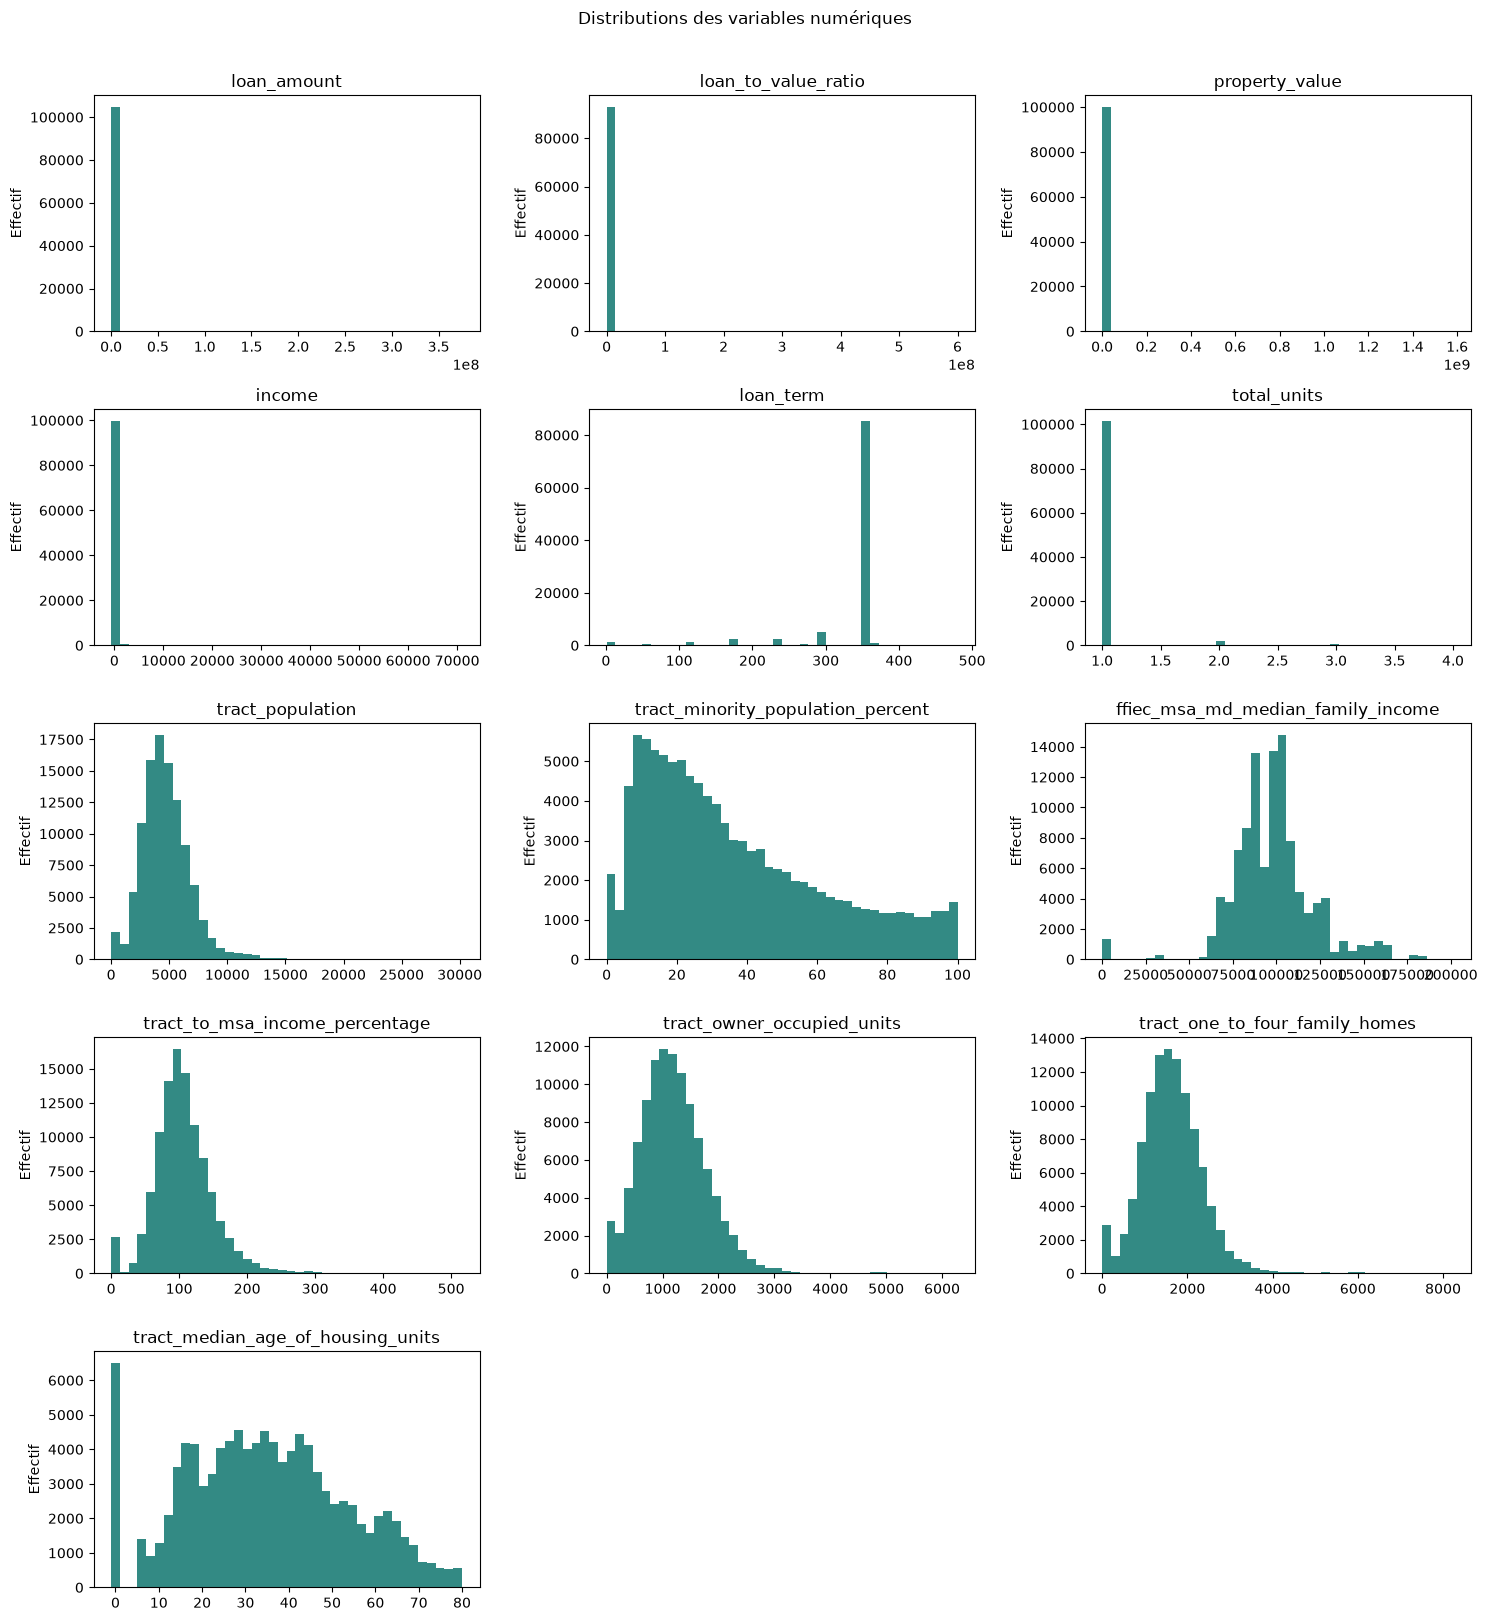

In [5]:
numeric_columns = [column for column in NUMERIC_COLUMNS if column in X.columns]
display(X[numeric_columns].describe(percentiles=[0.25, 0.5, 0.75]).T)

ncols = 3
nrows = int(np.ceil(len(numeric_columns) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(15, 3.2 * nrows))
axes = np.asarray(axes).reshape(-1)
for ax, column in zip(axes, numeric_columns):
    values = pd.to_numeric(X[column], errors="coerce").dropna()
    ax.hist(values, bins=40, color="#0f766e", alpha=0.85)
    ax.set_title(column)
    ax.set_ylabel("Effectif")
for ax in axes[len(numeric_columns):]:
    ax.set_visible(False)
fig.suptitle("Distributions des variables numériques", y=1.01)
fig.tight_layout()
plt.show()

## 6. Variables catégorielles

Les graphiques suivants montrent les modalités les plus fréquentes pour quelques variables représentatives. Ils ne convertissent pas les catégories en nombres ordonnés.

Nombre de variables catégorielles : 43
Variables affichées : ['derived_loan_product_type', 'state_code', 'debt_to_income_ratio', 'applicant_age', 'derived_race']


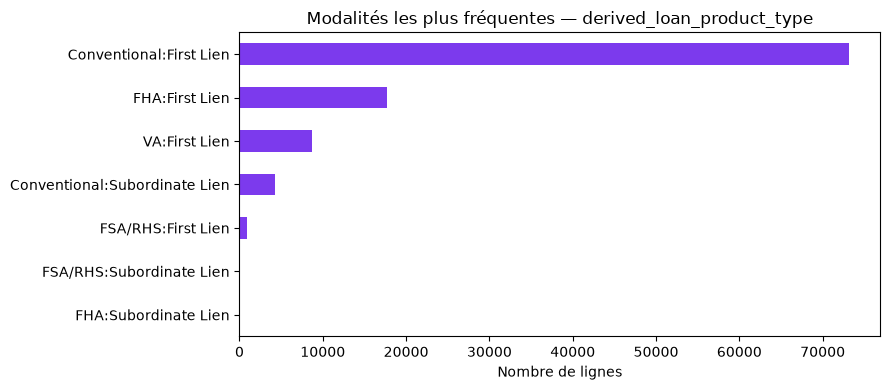

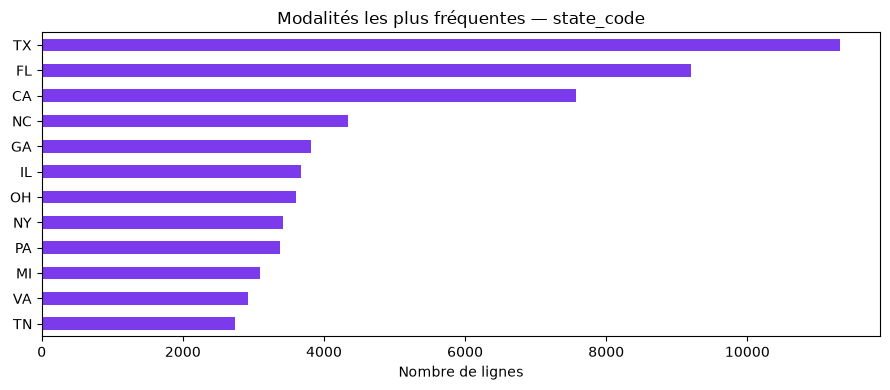

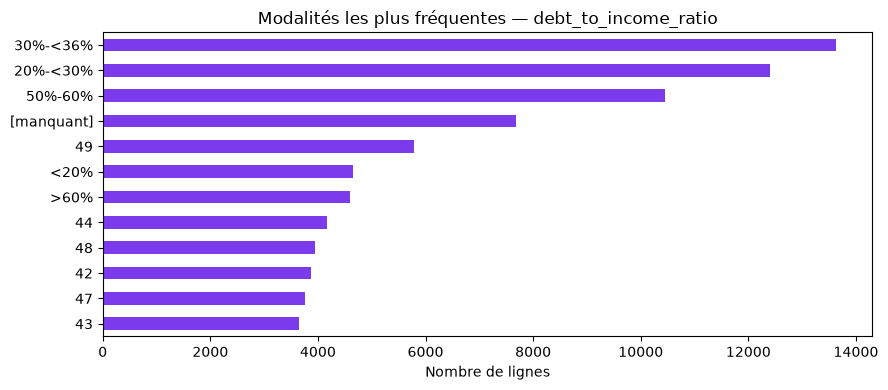

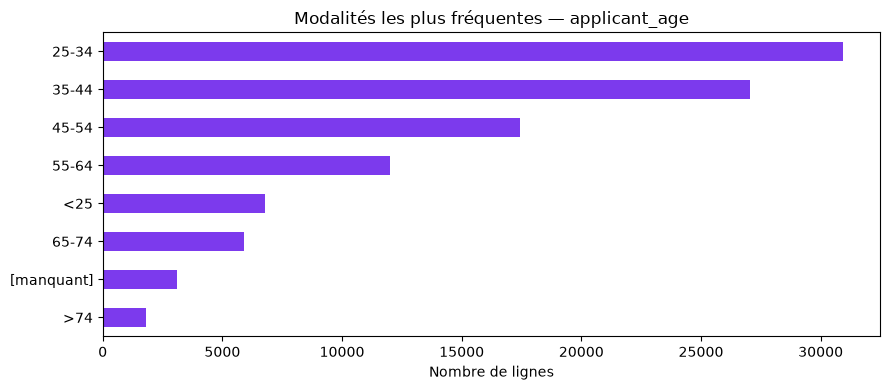

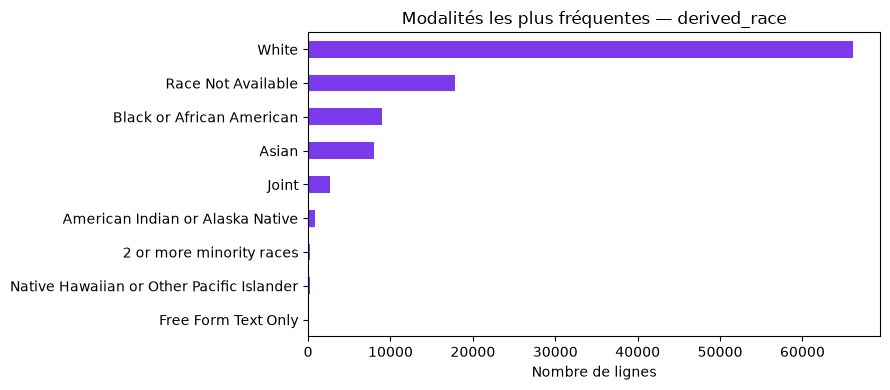

In [6]:
categorical_columns = [column for column in X.columns if column not in NUMERIC_COLUMNS]
selected_categories = [
    column for column in [
        "derived_loan_product_type",
        "state_code",
        "debt_to_income_ratio",
        "applicant_age",
        "derived_race",
    ]
    if column in categorical_columns
]
print(f"Nombre de variables catégorielles : {len(categorical_columns)}")
print("Variables affichées :", selected_categories)

for column in selected_categories:
    counts = X[column].replace("", pd.NA).fillna("[manquant]").value_counts().head(12).sort_values()
    ax = counts.plot(kind="barh", figsize=(9, 4), color="#7c3aed")
    ax.set_title(f"Modalités les plus fréquentes — {column}")
    ax.set_xlabel("Nombre de lignes")
    ax.set_ylabel("")
    plt.tight_layout()
    plt.show()

## 7. Taux d’acceptation descriptifs

Ces tableaux comparent la moyenne de la cible par modalité en affichant aussi les effectifs. Les petits groupes sont écartés pour rendre l’affichage moins instable. Ce sont des statistiques descriptives, pas une mesure d’effet causal ni une justification de décision.


derived_loan_product_type


,taux_acceptation,effectif
derived_loan_product_type,,
Conventional:Subordinate Lien,0.801863,4295
Conventional:First Lien,0.840098,73220
FSA/RHS:First Lien,0.860169,944
FHA:First Lien,0.870757,17734
VA:First Lien,0.912198,8690


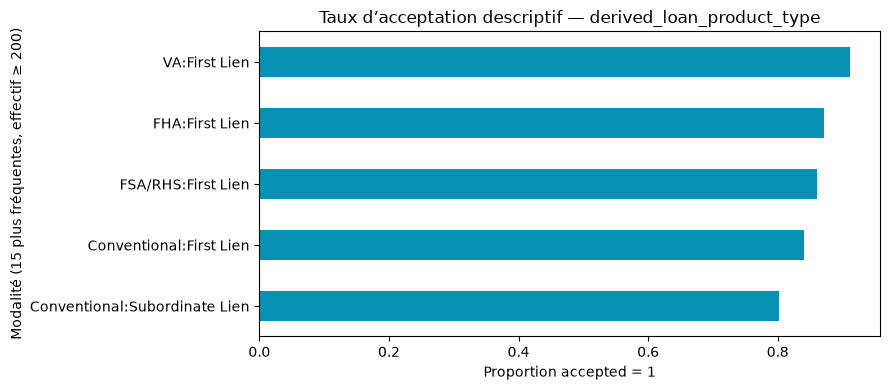


state_code


,taux_acceptation,effectif
state_code,,
SC,0.794487,2467
TX,0.808379,11314
FL,0.823478,9200
GA,0.825289,3812
TN,0.842836,2736
MI,0.849887,3091
NC,0.852867,4343
NY,0.856224,3422
IN,0.870889,2463


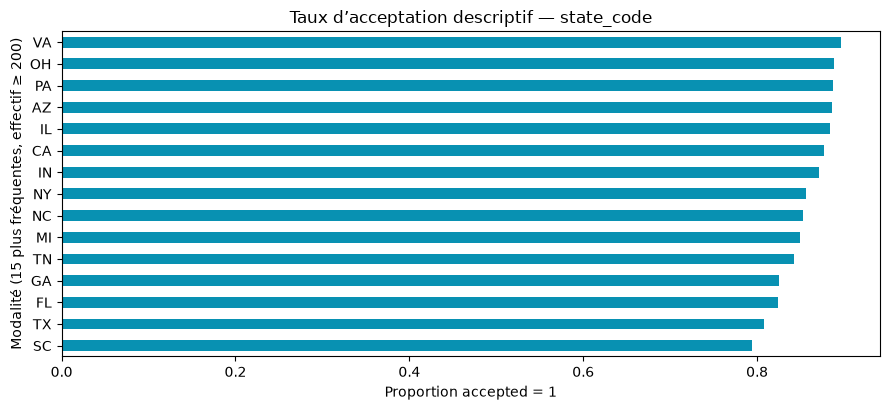


debt_to_income_ratio


,taux_acceptation,effectif
debt_to_income_ratio,,
>60%,0.120017,4591
50%-60%,0.753854,10445
<20%,0.781290,4650
[manquant],0.822373,7679
20%-<30%,0.897428,12401
47,0.902446,3762
48,0.902489,3938
42,0.907871,3875
45,0.908858,3511


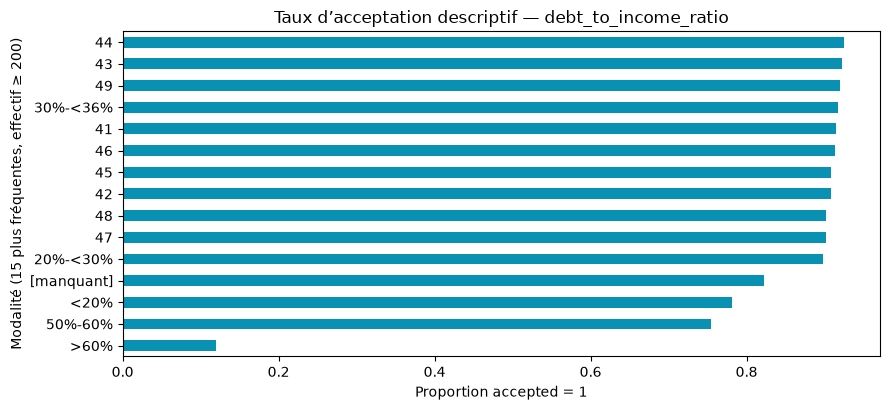


applicant_age


,taux_acceptation,effectif
applicant_age,,
<25,0.812509,6763
45-54,0.833859,17437
55-64,0.841324,11993
>74,0.849562,1828
35-44,0.852153,27055
65-74,0.853634,5903
25-34,0.865451,30933
[manquant],0.874676,3088


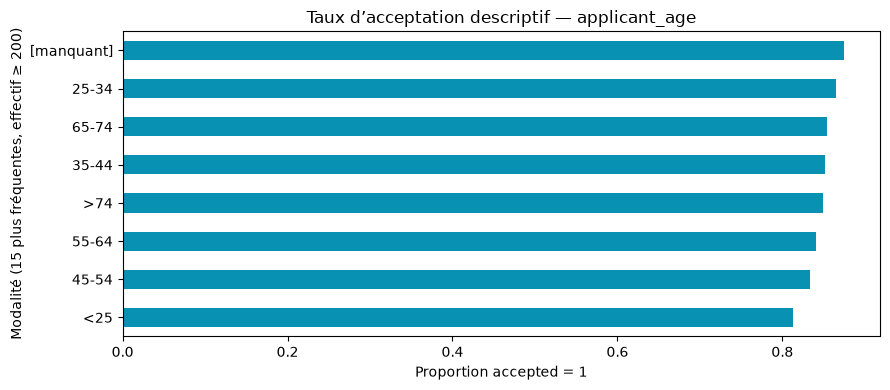


derived_race


,taux_acceptation,effectif
derived_race,,
2 or more minority races,0.687050,278
American Indian or Alaska Native,0.727160,810
Black or African American,0.738739,8991
Race Not Available,0.827551,17872
White,0.868078,66107
Joint,0.872239,2716
Asian,0.889125,8009


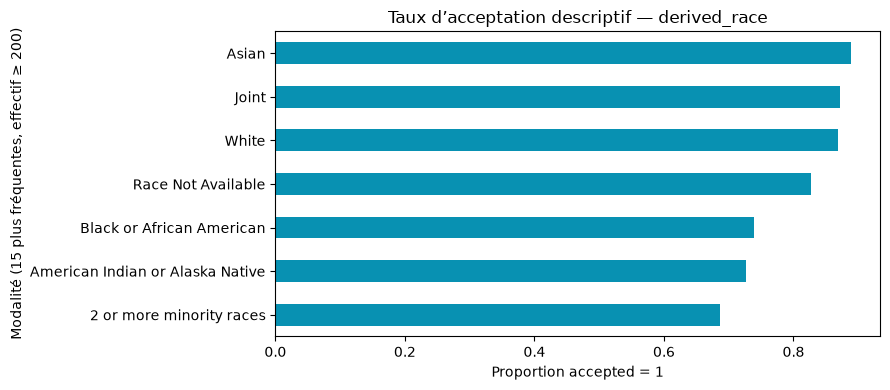

In [7]:
for column in selected_categories:
    analysis = pd.DataFrame({column: X[column].replace("", pd.NA).fillna("[manquant]"), config.target_column: y})
    rates = (
        analysis.groupby(column, dropna=False)[config.target_column]
        .agg(taux_acceptation="mean", effectif="size")
        .query("effectif >= 200")
        .sort_values("effectif", ascending=False)
        .head(15)
        .sort_values("taux_acceptation")
    )
    print(f"\n{column}")
    display(rates)
    if not rates.empty:
        ax = rates["taux_acceptation"].plot(kind="barh", figsize=(9, max(4, 0.28 * len(rates))), color="#0891b2")
        ax.set_title(f"Taux d’acceptation descriptif — {column}")
        ax.set_xlabel("Proportion accepted = 1")
        ax.set_ylabel("Modalité (15 plus fréquentes, effectif ≥ 200)")
        plt.tight_layout()
        plt.show()

## 8. Corrélations numériques

La corrélation de Pearson est calculée uniquement entre mesures numériques continues et la cible binaire. Elle ne décrit pas les relations non linéaires et ne s’applique pas aux codes catégoriels.

,corrélation avec accepted
ffiec_msa_md_median_family_income,0.172532
tract_to_msa_income_percentage,0.161982
tract_owner_occupied_units,0.124319
loan_term,0.123585
tract_population,0.114250
tract_one_to_four_family_homes,0.106929
tract_median_age_of_housing_units,0.070214
income,0.055580
loan_amount,0.018551
total_units,-0.011916


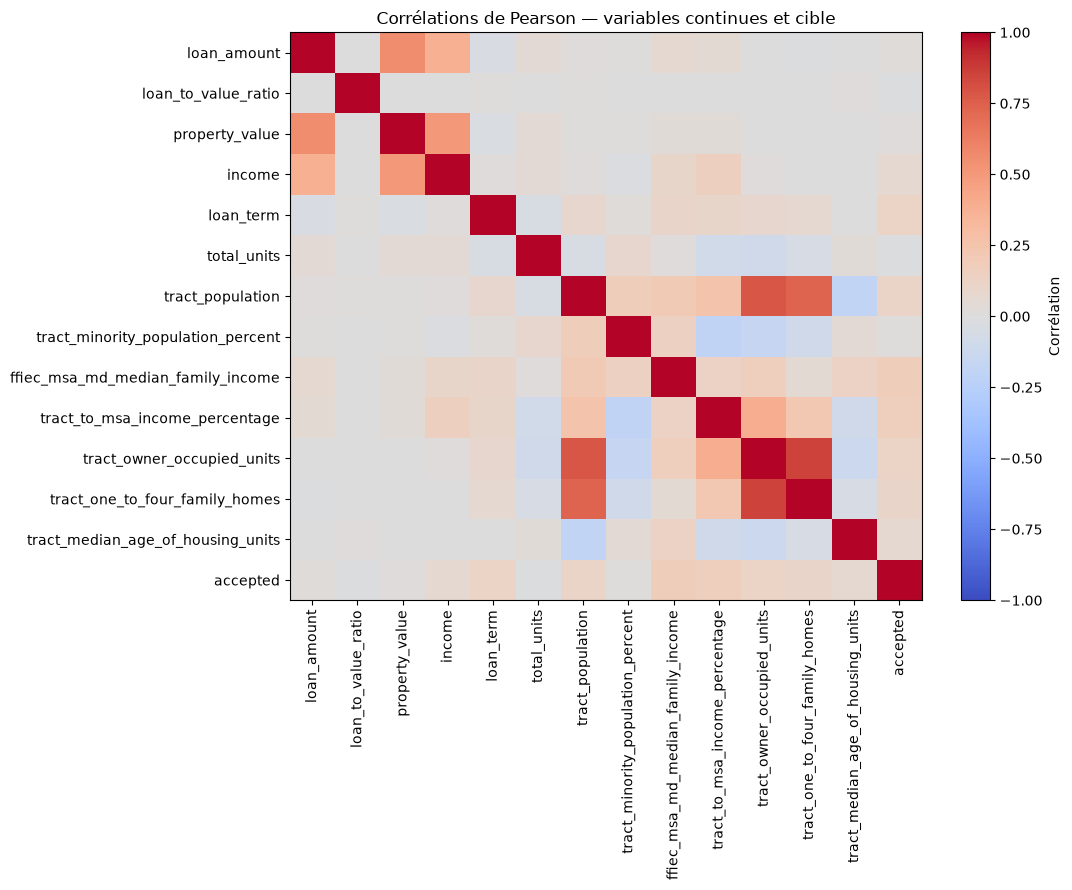

In [8]:
correlation_frame = X[numeric_columns].copy()
correlation_frame[config.target_column] = y
correlations = correlation_frame.corr(numeric_only=True)
display(correlations[config.target_column].drop(config.target_column).sort_values(key=lambda values: values.abs(), ascending=False).to_frame("corrélation avec accepted"))

fig, ax = plt.subplots(figsize=(11, 9))
image = ax.imshow(correlations, cmap="coolwarm", vmin=-1, vmax=1, aspect="auto")
ax.set_xticks(range(len(correlations.columns)), labels=correlations.columns, rotation=90)
ax.set_yticks(range(len(correlations.index)), labels=correlations.index)
ax.set_title("Corrélations de Pearson — variables continues et cible")
fig.colorbar(image, ax=ax, label="Corrélation")
fig.tight_layout()
plt.show()

## 9. Pour la suite

- Utiliser `src.train` pour comparer les modèles sur une partition de validation stratifiée et reproductible.
- La métrique de comparaison est le ROC-AUC calculé avec les probabilités de la classe `1`.
- Modifier les transformations et les paramètres dans une copie de `config.json` pour conserver plusieurs expériences.
- Après sélection, lancer `src.predict` pour réentraîner sur toutes les données étiquetées et produire le fichier Kaggle.

Les résultats obtenus sur ce notebook ne remplacent pas l’évaluation de validation et ne doivent pas servir à regarder les étiquettes du jeu de test, qui ne sont pas disponibles.